# Sesi 2 — 04. Prediksi 24 Jam ke Depan (Seluruh Hari Esok)

**Workshop Deep Learning untuk Mahasiswa Teknik Telekomunikasi — ITERA**

**Tugas:** dari trafik **beberapa jam terakhir**, prediksi aktivitas internet **24 jam berikutnya sekaligus** (seluruh hari esok). Operator membutuhkan ramalan seperti ini untuk merencanakan kapasitas, misalnya kapan sel boleh masuk *sleep mode* untuk menghemat energi.

Notebook ini melanjutkan `03_rnn_lstm_gru_vs_ann.ipynb`. Kodenya sama, hanya `HORIZON = 24`: output model berisi **24 angka**, bukan 1.

```
input  : W jam terakhir × 7 fitur [net, call, sms, jam (sin, cos), hari (sin, cos)]
output : net pada 24 jam berikutnya (24 angka)
```

Kita bandingkan secara adil:

| Model | Cara membaca input |
|---|---|
| Baseline naif | tanpa belajar: "sama dengan nilai terakhir / kemarin / minggu lalu" |
| **ANN** (MLP, Sesi 1) | semua jam diratakan jadi satu vektor, **urutan diabaikan** |
| **RNN** | membaca jam demi jam, membawa satu *hidden state* |
| **LSTM** | seperti RNN + *cell state* & 3 gerbang (*forget, input, output*) |
| **GRU** | versi ringkas LSTM: 2 gerbang (*reset, update*) |

dengan dua panjang jendela: **W = 24 jam** (1 hari) dan **W = 168 jam** (1 minggu).

| Bagian | Isi |
|---|---|
| 1 | Data & fitur |
| 2 | *Windowing*: mengubah deret waktu menjadi pasangan (X, y) |
| 3 | Baseline naif |
| 4 | Empat model |
| 5 | Training dengan *early stopping* |
| 6 | Eksperimen: 4 model × 2 jendela × 3 *seed* |
| 7 | Hasil & grafik prediksi |
| 8 | Error menurut jarak ramalan (1–24 jam) |
| 9 | Uji minggu Natal |
| 10 | Latihan |

In [1]:
import json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

# Palet warna ITERA (sama dengan slide)
NAVY, GOLD, RED, TEAL, GREEN, GRAY = "#0B1F3A", "#D4A017", "#C8102E", "#1E8C8C", "#2E9E6B", "#5A5A5A"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

WARNA_MODEL = {"ANN": GOLD, "RNN": RED, "LSTM": NAVY, "GRU": TEAL}

# ---- Pengaturan eksperimen ----
HORIZON = 24               # berapa jam ke depan yang diramal sekaligus
CEPAT = False             # True = 1 seed & epoch lebih sedikit (untuk laptop tanpa GPU)
WINDOWS = [24, 168]       # panjang jendela input (jam)
SEEDS = [0] if CEPAT else [0, 1, 2]
MAX_EPOCHS = 80 if CEPAT else 300
PATIENCE = 30             # early stopping: berhenti bila val loss tidak membaik 30 epoch
BATCH_SIZE = 64
LR = 1e-3

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
HASIL_DIR = Path("hasil") / ("h24")
HASIL_DIR.mkdir(parents=True, exist_ok=True)
print("PyTorch", torch.__version__, "| device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

PyTorch 2.14.0+cu130 | device: cuda NVIDIA GeForce RTX 5070


---
## 1. Data & Fitur

Selain `net`, `call`, `sms`, model perlu tahu **jam berapa** dan **hari apa**. Jam 23 dan jam 0 sebenarnya berdekatan, tetapi angka 23 dan 0 berjauhan. Solusinya: ubah jam menjadi titik pada lingkaran (sin, cos), sehingga jam 23 dan 0 bertetangga.

$$\text{jam}_{\sin} = \sin\!\left(2\pi \tfrac{\text{jam}}{24}\right), \qquad \text{jam}_{\cos} = \cos\!\left(2\pi \tfrac{\text{jam}}{24}\right)$$

In [2]:
df = pd.read_csv("data/milano_duomo_5060.csv", parse_dates=["waktu"]).set_index("waktu")

jam, hari = df.index.hour.values, df.index.dayofweek.values
df["jam_sin"], df["jam_cos"] = np.sin(2 * np.pi * jam / 24), np.cos(2 * np.pi * jam / 24)
df["hari_sin"], df["hari_cos"] = np.sin(2 * np.pi * hari / 7), np.cos(2 * np.pi * hari / 7)

FITUR = ["net", "call", "sms", "jam_sin", "jam_cos", "hari_sin", "hari_cos"]
TARGET = "net"
print(len(df), "jam,", len(FITUR), "fitur")
df[FITUR].head()

1344 jam, 7 fitur


,net,call,sms,jam_sin,jam_cos,hari_sin,hari_cos
waktu,,,,,,,
2013-11-04 00:00:00,847.950,14.265,32.569,0.000000,1.000000,0.0,1.0
2013-11-04 01:00:00,790.814,17.301,20.802,0.258819,0.965926,0.0,1.0
2013-11-04 02:00:00,737.321,3.039,12.912,0.500000,0.866025,0.0,1.0
2013-11-04 03:00:00,733.932,3.531,1.812,0.707107,0.707107,0.0,1.0
2013-11-04 04:00:00,785.195,2.337,3.188,0.866025,0.500000,0.0,1.0


### Pembagian waktu

Data deret waktu **tidak boleh diacak**: model dilatih dengan masa lalu dan diuji pada masa depan. Setiap sampel dimiliki oleh split tempat **jam target terakhirnya** berada. Jam target train dimulai dari minggu ke-2, sehingga jendela 168 jam selalu punya masa lalu yang lengkap; kedua jendela memakai **target train yang sama** agar adil.

| Split | Jam target | |
|---|---|---|
| train | 11 Nov – 8 Des | 4 minggu |
| val | 9 – 15 Des | *early stopping* |
| test | 16 – 22 Des | minggu normal |
| natal | 23 – 29 Des | uji tambahan |

In [3]:
t = df.index
SPLIT = {
    "train": (t >= "2013-11-11") & (t < "2013-12-09"),
    "val":   (t >= "2013-12-09") & (t < "2013-12-16"),
    "test":  (t >= "2013-12-16") & (t < "2013-12-23"),
    "natal": (t >= "2013-12-23"),
}
# Standarisasi memakai statistik data sebelum validasi saja (tidak mengintip masa depan)
sebelum_val = t < "2013-12-09"
mean = df.loc[sebelum_val, FITUR].mean()
std = df.loc[sebelum_val, FITUR].std()
Z = ((df[FITUR] - mean) / std).values.astype(np.float32)   # [1344, 7]
net = df[TARGET].values                                     # skala asli, untuk metrik

def ke_skala_asli(z):
    return z * std[TARGET] + mean[TARGET]

for nama, m in SPLIT.items():
    print(f"{nama:5s}: {t[m][0]:%d %b} – {t[m][-1]:%d %b}")

train: 11 Nov – 08 Dec
val  : 09 Dec – 15 Dec
test : 16 Dec – 22 Dec
natal: 23 Dec – 29 Dec


---
## 2. *Windowing*

Deret waktu diubah menjadi banyak pasangan (X, y) dengan **jendela geser**. Untuk setiap titik awal ramalan $i$:

```
X = jam  i-W … i-1   (W jam terakhir, semua fitur)
y = net  i … i+23   (24 jam ke depan)
```

Bentuk X untuk RNN/LSTM/GRU: **[jumlah sampel, W, 7]**, yaitu (*batch*, waktu, fitur). Bentuk y: **[jumlah sampel, 24]**.

In [4]:
def buat_jendela(Z, W, mask, H=HORIZON):
    """Sampel dengan titik awal i: X = Z[i-W:i], y = net terstandarisasi pada jam i … i+H-1.
    Sampel masuk split `mask` bila jam target terakhirnya (i+H-1) ada di split tsb."""
    awal = np.arange(W, len(Z) - H + 1)
    awal = awal[mask[awal + H - 1]]
    X = np.stack([Z[i - W:i] for i in awal])
    y = np.stack([Z[i:i + H, FITUR.index(TARGET)] for i in awal])
    return torch.tensor(X), torch.tensor(y), awal

for W in WINDOWS:
    X, y, _ = buat_jendela(Z, W, SPLIT["train"])
    print(f"W={W:3d} -> X: {tuple(X.shape)}  y: {tuple(y.shape)}")

W= 24 -> X: (672, 24, 7)  y: (672, 24)
W=168 -> X: (649, 168, 7)  y: (649, 24)


---
## 3. Baseline Naif

Sebelum *deep learning*, selalu tanyakan: **"Apakah tebakan sederhana sudah cukup?"** Model yang tidak mengalahkan baseline tidak berguna.

Metrik dihitung pada **skala asli**:

- **MAE**: rata-rata |error|
- **RMSE**: seperti MAE tetapi menghukum error besar lebih keras
- **MAPE**: rata-rata error dalam persen, mudah dibaca ("meleset ± x %")

In [5]:
def metrik(y_asli, y_pred):
    e = y_pred - y_asli
    return {"MAE": float(np.mean(np.abs(e))),
            "RMSE": float(np.sqrt(np.mean(e ** 2))),
            "MAPE": float(np.mean(np.abs(e) / y_asli) * 100)}

def target_asli(awal, H=HORIZON):
    return net[awal[:, None] + np.arange(H)]                 # [N, H]

def baseline_naif(awal, nama, H=HORIZON):
    h = np.arange(H)
    if nama == "Naif: nilai terakhir":                       # ulangi nilai jam i-1
        return np.repeat(net[awal - 1][:, None], H, axis=1)
    lag = 24 if nama == "Naif: kemarin" else 168             # jam yang sama kemarin / minggu lalu
    return net[awal[:, None] + h - lag]

NAIF = ["Naif: nilai terakhir", "Naif: kemarin", "Naif: minggu lalu"]
baris = []
for nama_split in ["test", "natal"]:
    _, _, awal = buat_jendela(Z, 168, SPLIT[nama_split])
    for nama in NAIF:
        baris.append({"model": nama, "split": nama_split, **metrik(target_asli(awal), baseline_naif(awal, nama))})
baseline = pd.DataFrame(baris)
baseline.pivot(index="model", columns="split", values=["MAE", "MAPE"]).round(1)

MAE           MAPE       
split                  natal    test  natal   test
model                                             
Naif: kemarin          915.1   563.4   42.4   23.7
Naif: minggu lalu     1431.6   466.1   97.7   19.1
Naif: nilai terakhir  2052.0  2769.3  131.1  125.8

---
## 4. Empat Model

Agar adil, ketiga model rekuren diberi **jumlah parameter yang hampir sama**. LSTM punya 4 blok bobot, GRU 3 blok, RNN 1 blok, sehingga ukuran *hidden*-nya berbeda.

ANN tidak bisa disamakan dengan cara yang sama: input ANN adalah W × 7 angka, sehingga **jumlah parameternya membengkak** ketika jendela diperpanjang. Ini salah satu kelemahan ANN untuk data berurutan.

In [6]:
class ANN(nn.Module):
    """MLP dari Sesi 1: jendela [W, 7] diratakan menjadi satu vektor W*7."""
    def __init__(self, W, n_fitur, n_out, hidden=32):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(W * n_fitur, hidden), nn.ReLU(),
                                 nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, n_out))
    def forward(self, x):
        return self.net(x)


class Rekuren(nn.Module):
    """RNN / LSTM / GRU satu lapis: baca jam demi jam, pakai hidden state terakhir untuk prediksi."""
    def __init__(self, jenis, n_fitur, hidden, n_out):
        super().__init__()
        sel = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[jenis]
        self.rnn = sel(n_fitur, hidden, batch_first=True)
        self.head = nn.Linear(hidden, n_out)
    def forward(self, x):                # x: [batch, W, fitur]
        out, _ = self.rnn(x)             # out: [batch, W, hidden]
        return self.head(out[:, -1])     # hidden state di jam terakhir -> HORIZON angka


HIDDEN = {"RNN": 68, "LSTM": 33, "GRU": 38}   # dipilih agar parameter ketiganya hampir sama

def buat_model(nama, W):
    if nama == "ANN":
        return ANN(W, len(FITUR), HORIZON)
    return Rekuren(nama, len(FITUR), HIDDEN[nama], HORIZON)

def n_param(model):
    return sum(p.numel() for p in model.parameters())

MODELS = ["ANN", "RNN", "LSTM", "GRU"]
pd.DataFrame({f"W={W}": {m: n_param(buat_model(m, W)) for m in MODELS} for W in WINDOWS})

,W=24,W=168
ANN,7256,39512
RNN,6892,6892
LSTM,6360,6360
GRU,6294,6294


---
## 5. Training dengan *Early Stopping*

Sama seperti Sesi 1: loss **MSE**, optimizer **Adam**, *mini-batch*. Bobot terbaik (val loss terendah) disimpan, dan training berhenti bila val loss tidak membaik selama `PATIENCE` epoch.

In [7]:
def latih(nama, W, seed):
    torch.manual_seed(seed)
    np.random.seed(seed)
    Xtr, ytr, _ = buat_jendela(Z, W, SPLIT["train"])
    Xva, yva, _ = buat_jendela(Z, W, SPLIT["val"])
    Xtr, ytr, Xva, yva = Xtr.to(DEVICE), ytr.to(DEVICE), Xva.to(DEVICE), yva.to(DEVICE)

    model = buat_model(nama, W).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.MSELoss()
    g = torch.Generator().manual_seed(seed)

    riwayat, terbaik, state_terbaik, sabar = [], float("inf"), None, 0
    for epoch in range(MAX_EPOCHS):
        model.train()
        for b in torch.randperm(len(Xtr), generator=g).split(BATCH_SIZE):
            opt.zero_grad()
            loss = loss_fn(model(Xtr[b]), ytr[b])
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            tr = loss_fn(model(Xtr), ytr).item()
            va = loss_fn(model(Xva), yva).item()
        riwayat.append((tr, va))
        if va < terbaik:
            terbaik, sabar = va, 0
            state_terbaik = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            sabar += 1
            if sabar >= PATIENCE:
                break
    model.load_state_dict(state_terbaik)
    return model, np.array(riwayat)


def prediksi(model, W, nama_split):
    X, _, awal = buat_jendela(Z, W, SPLIT[nama_split])
    model.eval()
    with torch.no_grad():
        z = model(X.to(DEVICE)).cpu().numpy()       # [N, HORIZON]
    return ke_skala_asli(z), awal

---
## 6. Eksperimen

4 model × 2 jendela × 3 *seed*. *Seed* berbeda = inisialisasi bobot & urutan batch berbeda. Dengan data sekecil ini hasil satu kali run bisa kebetulan, jadi kita laporkan **rata-rata ± simpangan baku**.

In [8]:
hasil, riwayat_semua, pred_semua, model_simpan = [], {}, {}, {}
for W in WINDOWS:
    for nama in MODELS:
        for seed in SEEDS:
            t0 = time.time()
            model, riwayat = latih(nama, W, seed)
            detik = time.time() - t0
            riwayat_semua[(nama, W, seed)] = riwayat
            if seed == SEEDS[0]:
                model_simpan[(nama, W)] = model
            for nama_split in ["test", "natal"]:
                pred, awal = prediksi(model, W, nama_split)
                pred_semua[(nama, W, seed, nama_split)] = (pred, awal)
                hasil.append({"model": nama, "W": W, "seed": seed, "split": nama_split,
                              "epoch": len(riwayat), "detik": detik, "param": n_param(model),
                              **metrik(target_asli(awal), pred)})
            r = hasil[-2]
            print(f"W={W:3d} {nama:4s} seed={seed}  epoch={r['epoch']:3d}  {detik:5.1f} s  test MAE={r['MAE']:6.1f}  MAPE={r['MAPE']:4.1f}%")

hasil = pd.DataFrame(hasil)
hasil.to_csv(HASIL_DIR / "hasil_eksperimen.csv", index=False)

W= 24 ANN  seed=0  epoch=143    2.3 s  test MAE= 542.2  MAPE=23.1%


W= 24 ANN  seed=1  epoch=171    1.6 s  test MAE= 510.0  MAPE=22.1%


W= 24 ANN  seed=2  epoch=149    1.4 s  test MAE= 528.0  MAPE=22.8%


W= 24 RNN  seed=0  epoch=194    2.1 s  test MAE= 479.6  MAPE=17.2%


W= 24 RNN  seed=1  epoch=272    3.0 s  test MAE= 494.2  MAPE=17.5%


...

W=168 LSTM seed=1  epoch=198    2.6 s  test MAE= 518.8  MAPE=18.1%


W=168 LSTM seed=2  epoch=164    2.2 s  test MAE= 524.5  MAPE=18.6%


W=168 GRU  seed=0  epoch=164    2.0 s  test MAE= 520.7  MAPE=18.8%


W=168 GRU  seed=1  epoch=218    2.7 s  test MAE= 495.2  MAPE=17.1%


W=168 GRU  seed=2  epoch=170    2.1 s  test MAE= 502.9  MAPE=18.0%


---
## 7. Hasil

### 7.1 Tabel perbandingan (minggu test 16–22 Des)

In [9]:
test = hasil[hasil.split == "test"]
ringkas = test.groupby(["W", "model"]).agg(
    param=("param", "first"), epoch=("epoch", "mean"), detik=("detik", "mean"),
    MAE=("MAE", "mean"), MAE_sd=("MAE", "std"), RMSE=("RMSE", "mean"), MAPE=("MAPE", "mean"), MAPE_sd=("MAPE", "std"),
).reset_index()
b = baseline[baseline.split == "test"].assign(W="-")[["W", "model", "MAE", "RMSE", "MAPE"]]
tabel = pd.concat([b, ringkas], ignore_index=True)
tabel.to_csv(HASIL_DIR / "ringkasan_test.csv", index=False)
tabel.round(1)

,W,model,MAE,RMSE,MAPE,param,epoch,detik,MAE_sd,MAPE_sd
0,-,Naif: nilai terakhir,2769.3,3466.6,125.8,NaN,NaN,NaN,NaN,NaN
1,-,Naif: kemarin,563.4,879.9,23.7,NaN,NaN,NaN,NaN,NaN
2,-,Naif: minggu lalu,466.1,752.1,19.1,NaN,NaN,NaN,NaN,NaN
3,24,ANN,526.8,689.5,22.7,7256.0,154.3,1.7,16.1,0.5
4,24,GRU,503.3,697.6,17.7,6294.0,193.0,2.2,6.6,0.8
5,24,LSTM,496.7,688.9,16.7,6360.0,208.7,2.5,10.2,0.8
6,24,RNN,486.2,674.2,17.1,6892.0,208.7,2.3,7.4,0.4
7,168,ANN,510.0,660.0,20.3,39512.0,113.7,1.0,28.5,1.8
8,168,GRU,506.3,691.7,18.0,6294.0,184.0,2.3,13.1,0.9
9,168,LSTM,513.6,705.8,17.7,6360.0,210.7,2.8,14.3,1.1


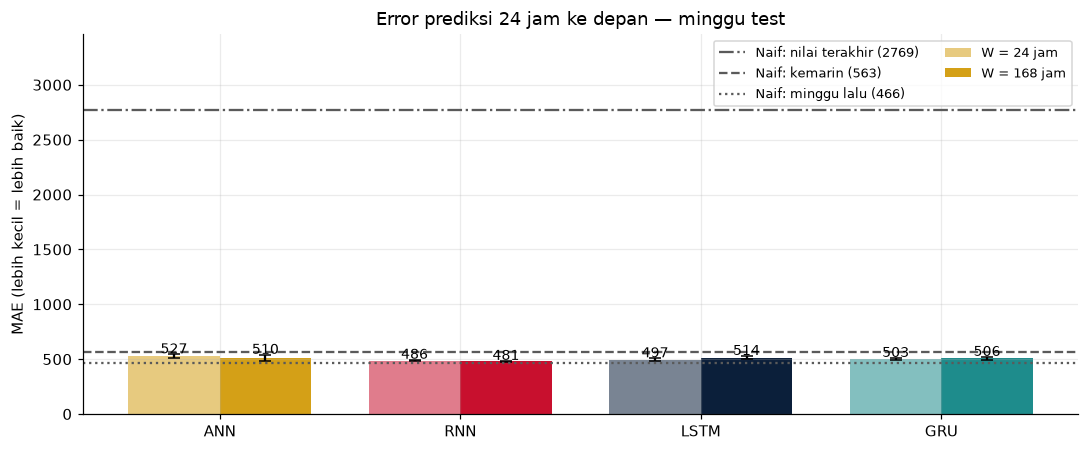

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.2))
lebar = 0.38
x = np.arange(len(MODELS))
for j, (W, alpha) in enumerate([(24, 0.55), (168, 1.0)]):
    r = ringkas[ringkas.W == W].set_index("model").loc[MODELS]
    xs = x + (j - 0.5) * lebar
    ax.bar(xs, r.MAE, lebar, yerr=r.MAE_sd, capsize=4,
           color=[WARNA_MODEL[m] for m in MODELS], alpha=alpha, label=f"W = {W} jam")
    for xi, v, sd in zip(xs, r.MAE, r.MAE_sd):
        ax.text(xi, v + sd + 10, f"{v:.0f}", ha="center", fontsize=9)
gaya_naif = {"Naif: nilai terakhir": "-.", "Naif: kemarin": "--", "Naif: minggu lalu": ":"}
for nama, gaya in gaya_naif.items():
    v = baseline.query("split == 'test' and model == @nama").MAE.item()
    ax.axhline(v, color=GRAY, ls=gaya, lw=1.5, label=f"{nama} ({v:.0f})")
ax.set_xticks(x, MODELS); ax.set_ylabel("MAE (lebih kecil = lebih baik)")
ax.set_ylim(0, max(ax.get_ylim()[1], baseline[baseline.split == "test"].MAE.max() * 1.25))
ax.set_title(f"Error prediksi {HORIZON} jam ke depan — minggu test")
ax.legend(fontsize=8.5, ncol=2, loc="upper right")
plt.tight_layout()
plt.savefig(HASIL_DIR / "perbandingan_mae.png", dpi=200, bbox_inches="tight")
plt.show()

### 7.2 Prediksi vs data asli

Setiap hari pada pukul 00.00, model meramal **24 jam ke depan sekaligus**. Grafik di bawah menyambung 7 ramalan harian tersebut.

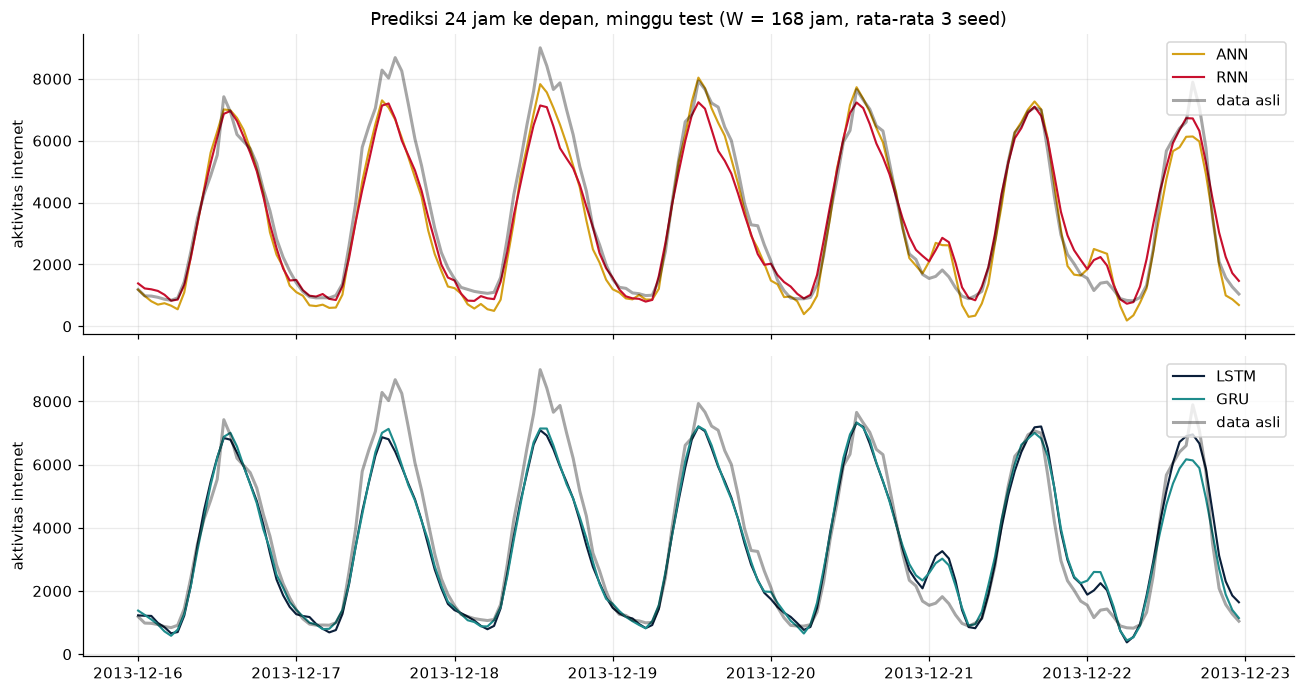

In [11]:
def ramalan_harian(pred, awal, nama_split):
    """Ambil ramalan yang titik awalnya berada di split, setiap HORIZON jam, lalu sambung."""
    mulai = np.where(SPLIT[nama_split])[0][0]
    pilih = np.where((awal >= mulai) & ((awal - mulai) % HORIZON == 0))[0]
    jam = (awal[pilih][:, None] + np.arange(HORIZON)).ravel()
    return jam, pred[pilih].ravel()

W_PLOT = 168
fig, axes = plt.subplots(2, 1, figsize=(12, 6.4), sharex=True)
for ax, pasangan in zip(axes, [("ANN", "RNN"), ("LSTM", "GRU")]):
    for nama in pasangan:
        semua = [ramalan_harian(*pred_semua[(nama, W_PLOT, s, "test")], "test") for s in SEEDS]
        jam_plot = semua[0][0]
        ax.plot(df.index[jam_plot], np.mean([p for _, p in semua], axis=0), color=WARNA_MODEL[nama], lw=1.4, label=nama)
    ax.plot(df.index[jam_plot], net[jam_plot], color="black", lw=2, alpha=0.35, label="data asli")
    ax.set_ylabel("aktivitas internet"); ax.legend(loc="upper right")
axes[0].set_title(f"Prediksi {HORIZON} jam ke depan, minggu test (W = {W_PLOT} jam, rata-rata {len(SEEDS)} seed)")
plt.tight_layout()
plt.savefig(HASIL_DIR / "prediksi_test.png", dpi=200, bbox_inches="tight")
plt.show()

### 7.3 Kurva belajar

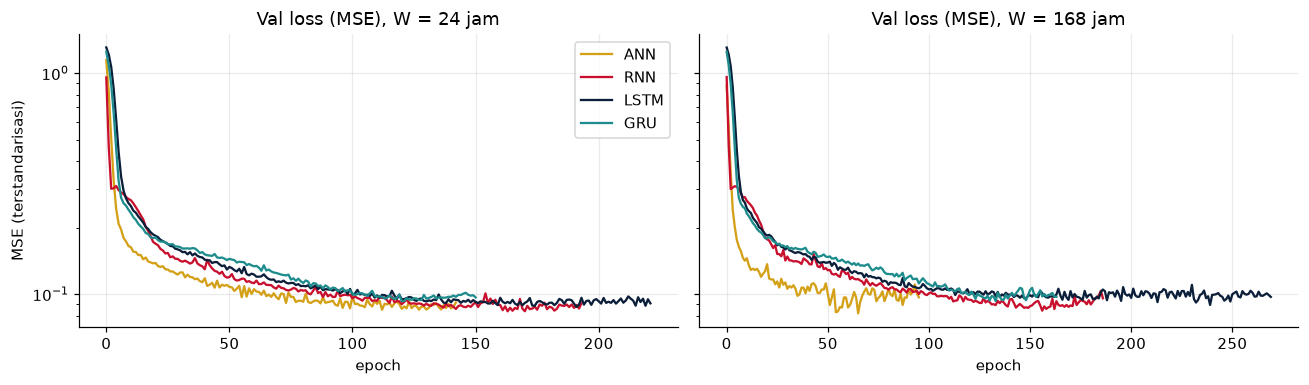

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, W in zip(axes, WINDOWS):
    for nama in MODELS:
        r = riwayat_semua[(nama, W, SEEDS[0])]
        ax.plot(r[:, 1], color=WARNA_MODEL[nama], lw=1.5, label=nama)
    ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_title(f"Val loss (MSE), W = {W} jam")
axes[0].set_ylabel("MSE (terstandarisasi)"); axes[0].legend()
plt.tight_layout()
plt.savefig(HASIL_DIR / "kurva_belajar.png", dpi=200, bbox_inches="tight")
plt.show()

---
## 8. Error Menurut Jarak Ramalan

Ramalan untuk 1 jam ke depan tentu lebih mudah daripada 24 jam ke depan. Seberapa cepat error tumbuh, dan model mana yang paling tahan?

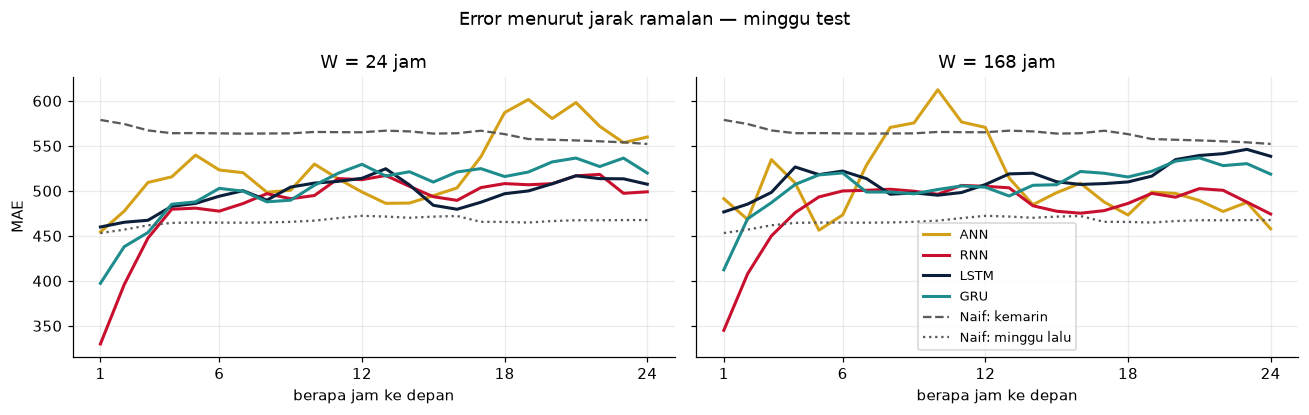

In [13]:
def mae_per_langkah(pred, awal):
    return np.mean(np.abs(pred - target_asli(awal)), axis=0)        # [HORIZON]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
h = np.arange(1, HORIZON + 1)
_, _, awal_test = buat_jendela(Z, 168, SPLIT["test"])
for ax, W in zip(axes, WINDOWS):
    for nama in MODELS:
        m = np.mean([mae_per_langkah(*pred_semua[(nama, W, s, "test")]) for s in SEEDS], axis=0)
        ax.plot(h, m, color=WARNA_MODEL[nama], lw=2, label=nama)
    for nama, gaya in [("Naif: kemarin", "--"), ("Naif: minggu lalu", ":")]:
        ax.plot(h, mae_per_langkah(baseline_naif(awal_test, nama), awal_test), color=GRAY, ls=gaya, lw=1.5, label=nama)
    ax.set_xlabel("berapa jam ke depan"); ax.set_title(f"W = {W} jam"); ax.set_xticks([1, 6, 12, 18, 24])
axes[0].set_ylabel("MAE"); axes[1].legend(fontsize=8.5)
fig.suptitle("Error menurut jarak ramalan — minggu test")
plt.tight_layout()
plt.savefig(HASIL_DIR / "error_per_jarak.png", dpi=200, bbox_inches="tight")
plt.show()

---
## 9. Uji Minggu Natal

Semua model dilatih dengan minggu-minggu normal. Bagaimana kalau pola berubah?

In [14]:
natal = hasil[hasil.split == "natal"].groupby(["W", "model"]).MAE.agg(["mean", "std"]).round(1)
print(baseline[baseline.split == "natal"][["model", "MAE", "MAPE"]].round(1).to_string(index=False))
natal

               model    MAE  MAPE
Naif: nilai terakhir 2052.0 131.1
       Naif: kemarin  915.1  42.4
   Naif: minggu lalu 1431.6  97.7


mean   std
W   model              
24  ANN    1199.4  30.9
    GRU    1108.1  33.5
    LSTM   1152.3   4.5
    RNN    1101.6  17.7
168 ANN    1283.6  45.9
    GRU    1109.1  19.3
    LSTM   1158.0  13.1
    RNN    1092.5  21.9

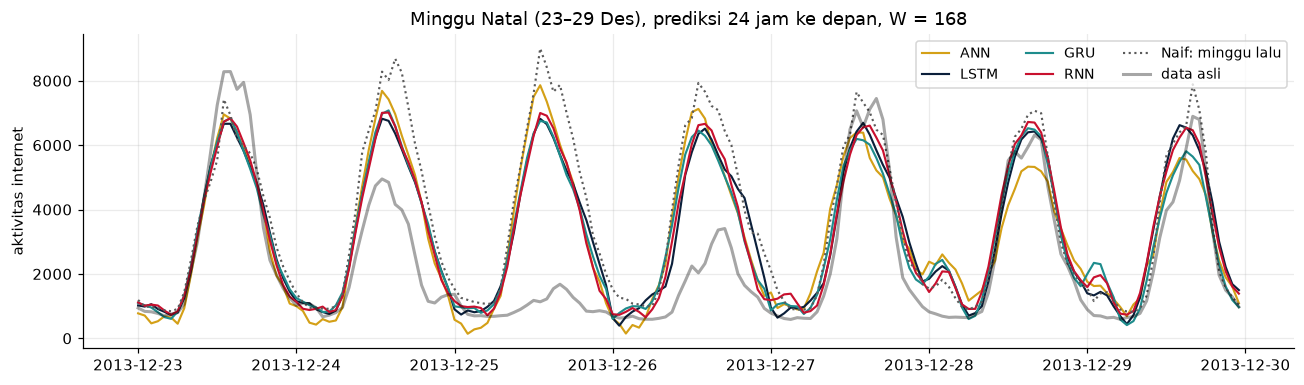

In [15]:
fig, ax = plt.subplots(figsize=(12, 3.6))
jam_plot = None
for nama in ["ANN", "LSTM", "GRU", "RNN"]:
    semua = [ramalan_harian(*pred_semua[(nama, 168, s, "natal")], "natal") for s in SEEDS]
    jam_plot = semua[0][0]
    ax.plot(df.index[jam_plot], np.mean([p for _, p in semua], axis=0), color=WARNA_MODEL[nama], lw=1.4, label=nama)
ax.plot(df.index[jam_plot], net[jam_plot - 168], color=GRAY, ls=":", lw=1.4, label="Naif: minggu lalu")
ax.plot(df.index[jam_plot], net[jam_plot], color="black", lw=2, alpha=0.35, label="data asli")
ax.set_ylabel("aktivitas internet"); ax.legend(loc="upper right", ncol=3, fontsize=9)
ax.set_title(f"Minggu Natal (23–29 Des), prediksi {HORIZON} jam ke depan, W = 168")
plt.tight_layout()
plt.savefig(HASIL_DIR / "prediksi_natal.png", dpi=200, bbox_inches="tight")
plt.show()

In [16]:
# Simpan ringkasan dalam JSON (dipakai untuk slide)
ringkasan = {
    "horizon": HORIZON,
    "device": torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu",
    "torch": torch.__version__, "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
    "baseline": baseline.round(2).to_dict(orient="records"),
    "test": ringkas.round(2).to_dict(orient="records"),
    "test_per_seed": test[["W", "model", "seed", "MAE", "MAPE"]].round(2).to_dict(orient="records"),
    "natal": hasil[hasil.split == "natal"].groupby(["W", "model"]).MAE.agg(["mean", "std"]).round(2).reset_index().to_dict(orient="records"),
}
(HASIL_DIR / "ringkasan.json").write_text(json.dumps(ringkasan, indent=2))
print("Tersimpan di", HASIL_DIR)

Tersimpan di hasil/h24


---
## 10. Latihan

1. **Horizon.** Coba `HORIZON = 6` atau `48`. Bagaimana urutan model berubah?
2. **Fitur kalender.** Hapus `hari_sin` & `hari_cos`. Apakah model masih tahu bedanya hari kerja dan akhir pekan?
3. **Gabungkan dengan baseline.** Latih model untuk memprediksi *selisih* terhadap "Naif: minggu lalu", bukan nilai mentahnya.
4. **Kapan gerbang penting?** Lanjut ke `05_uji_ingatan.ipynb`.